# Caso exemplo de composição de portifólio

Ativos considerados: MATD3; DIRR3; ECOR3; OFSA3; GOAU3; BOVX11.

## Bibliotecas

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import yfinance as yf

## Parâmetros de Entrada:

In [2]:
ativos       = ["MATD3.SA","DIRR3.SA","ECOR3.SA","OFSA3.SA","GOAU3.SA","BOVX11.SA"]
data_inicial = "2021-06-21" # formato: YYYY-MM-DD (Ano-Mês-Dia)
#data_final   = "2026-11-14" # Até a data atual

## Visualização do domínio todo (normalizado)

In [3]:
def vis_preco_historico_total(dataframe,normalizar = True):
    dataframe = dataframe['Close'][ativos].dropna()
    if normalizar:
        dataframe = (dataframe/dataframe.iloc[0]) * 100
        dataframe.plot(figsize = [15,8])
    else:
        dataframe.plot(figsize=[15,8])
    plt.xlabel('Data',  fontsize=21)
    plt.ylabel('Preço de Fechamento (normalizado)',fontsize=21)
    #plt.yscale('log')
    plt.xticks(fontsize=20)
    plt.yticks(fontsize=20)
    plt.legend(loc = 'best', fontsize=14);
    plt.show()
    return None

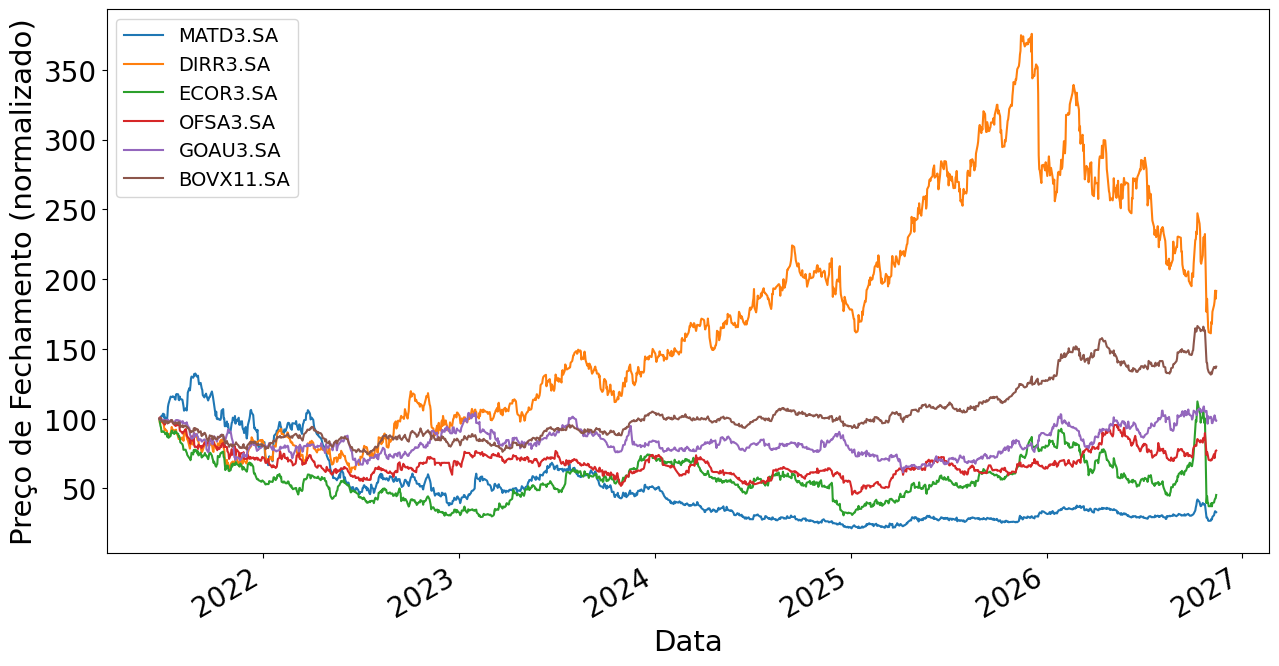

In [4]:
df  =  yf.download(ativos, start=data_inicial, auto_adjust=False, progress=False)
vis_preco_historico_total(df)

## Cálculo da Fronteira Eficiente

In [5]:
def monte_carlo_de_portifolios(
    df,
    Resample="YE",
    num_pontos=500000,
    min_weight=0.10,
    max_weight=0.80,
    lote_inicial=1000000,
    max_iter=100,
):
  """Simulação de Monte Carlo vetorizada com restrições de limites,

  validação matemática de viabilidade e trava de segurança contra loop infinito.
  """
  if isinstance(df.columns, pd.MultiIndex) and "Close" in df.columns.levels[0]:
    df = df["Close"]

  n_atv = len(df.columns)

  # --- 1. Validação Matemática de Viabilidade dos Limites ---
  if min_weight > max_weight:
    raise ValueError(
        f"O peso mínimo ({min_weight}) não pode ser maior que o peso máximo"
        f" ({max_weight})."
    )
  if min_weight * n_atv > 1.0:
    raise ValueError(
        f"Erro de viabilidade: O peso mínimo ({min_weight}) multiplicado por"
        f" {n_atv} ativos ultrapassa 100% (soma máxima possível seria"
        f" {min_weight * n_atv * 100:.1f}%)."
    )
  if max_weight * n_atv < 1.0:
    raise ValueError(
        f"Erro de viabilidade: O peso máximo ({max_weight}) multiplicado por"
        f" {n_atv} ativos não é suficiente para atingir 100% (soma máxima"
        f" possível seria {max_weight * n_atv * 100:.1f}%)."
    )

  ind_er = (
      df.resample(Resample).last().pct_change(fill_method=None).mean()
  )
  cov_matrix = df.pct_change(fill_method=None).cov()

  cov_np = cov_matrix.to_numpy()
  er_np = ind_er.to_numpy()

  pesos_validos = []
  coletados = 0
  iteracao = 0  # Contador de segurança para o loop while

  # --- 2. Loop com Trava de Segurança contra Loop Infinito ---
  while coletados < num_pontos:
    if iteracao >= max_iter:
      raise RuntimeError(
          f"Limite máximo de {max_iter} iterações atingido. Apenas"
          f" {coletados} de {num_pontos} portfólios válidos foram coletados."
          " Suas restrições de min/max estão excessivamente restritivas para"
          " o número de ativos."
      )

    # Gera o lote de pesos e normaliza
    pesos_raw = np.random.uniform(0, 1, size=(lote_inicial, n_atv))
    pesos = pesos_raw / np.sum(pesos_raw, axis=1, keepdims=True)

    # Aplica a máscara booleana de validação dos limites
    mask = np.all((pesos >= min_weight) & (pesos <= max_weight), axis=1)
    validos = pesos[mask]

    if len(validos) > 0:
      pesos_validos.append(validos)
      coletados += len(validos)

    iteracao += 1

  # Concatena e recorta exatamente na quantidade solicitada
  pesos_final = np.vstack(pesos_validos)[:num_pontos]

  # Cálculos vetorizados de Retorno e Risco
  p_ret = pesos_final @ er_np
  var = np.sum((pesos_final @ cov_np) * pesos_final, axis=1)
  p_vol = np.sqrt(var) * np.sqrt(252)

  # Montagem do DataFrame
  data = {"Retorno": p_ret, "Risco": p_vol}
  for counter, symbol in enumerate(df.columns.tolist()):
    data["peso " + symbol] = pesos_final[:, counter]

  return pd.DataFrame(data)

In [6]:
portifolios_teste = monte_carlo_de_portifolios(df,num_pontos=5)
display(portifolios_teste)

,Retorno,Risco,peso BOVX11.SA,peso DIRR3.SA,peso ECOR3.SA,peso GOAU3.SA,peso MATD3.SA,peso OFSA3.SA
0,0.124000,0.302167,0.104664,0.274349,0.220179,0.111399,0.163370,0.126038
1,0.104407,0.252273,0.165324,0.228507,0.113674,0.198607,0.111786,0.182103
2,0.082458,0.261155,0.226892,0.172698,0.101605,0.110549,0.226871,0.161385
3,0.077544,0.259130,0.167148,0.166422,0.104146,0.148455,0.220206,0.193623
4,0.097407,0.277424,0.105997,0.160904,0.202101,0.150584,0.172810,0.207604


In [7]:
def plotar_fronteira_eficiente(
    df,
    rf_poupanca=0.0829,
    rf_cdi=0.1423,
    rf_ipca=0.0463,
    grau=2,
    retorno_alvo=0.14,
    ):
    """Calcula os portfólios de destaque, realiza o ajuste polinomial,
  
    destaca opcionalmente um portfólio alvo por retorno e plota o gráfico.
    """
    portfolios = monte_carlo_de_portifolios(df)

    # 1. Identificação dos portfólios de destaque padrão
    min_vol_port = portfolios.loc[portfolios["Risco"].idxmin()]
    opt_ris_por0 = portfolios.loc[
        ((portfolios["Retorno"] - rf_poupanca) / portfolios["Risco"]).idxmax()
    ]
    opt_ris_por1 = portfolios.loc[
        ((portfolios["Retorno"] - rf_cdi) / portfolios["Risco"]).idxmax()
    ]
    opt_ris_por2 = portfolios.loc[
        ((portfolios["Retorno"] - rf_ipca) / portfolios["Risco"]).idxmax()
    ]   
    # Seleção do portfólio ótimo para um retorno alvo (se fornecido)
    portfolio_alvo = None
    if retorno_alvo is not None:
      candidatos = portfolios[portfolios["Retorno"] >= retorno_alvo]    
      if candidatos.empty:
        print(
            "Aviso: O retorno desejado é maior que o retorno máximo simulado."
            " Retornando o portfólio de maior retorno."
        )
        portfolio_alvo = portfolios.loc[portfolios["Retorno"].idxmax()]
      else:
        idx_otimo = candidatos["Risco"].idxmin()
        portfolio_alvo = portfolios.loc[idx_otimo]  
    # 2. Ajuste polinomial (fit) da Fronteira Eficiente
    x = np.array(
        [
            min_vol_port["Risco"],
            opt_ris_por0["Risco"],
            opt_ris_por1["Risco"],
            opt_ris_por2["Risco"],
            portfolio_alvo["Risco"]
        ]
    )
    y = np.array(
        [
            min_vol_port["Retorno"],
            opt_ris_por0["Retorno"],
            opt_ris_por1["Retorno"],
            opt_ris_por2["Retorno"],
            portfolio_alvo["Retorno"]
        ]
    )   
    z = np.polyfit(y, x, grau)  # x em função de y
    f = np.poly1d(z)    
    y_new = np.linspace(y.min() - 0.05, y.max() + 0.02, 200)
    x_new = f(y_new)    
    # 3. Construção do Gráfico
    plt.figure(figsize=(15, 8))
    xx = portfolios["Risco"]
    yy = portfolios["Retorno"]
    s1 = 400    
    plt.scatter(
        xx,
        yy,
        c="g",
        marker="o",
        s=50,
        alpha=0.4,
        label="Portfólios Simulados",
    )
    plt.scatter(
        min_vol_port["Risco"],
        min_vol_port["Retorno"],
        c="b",
        marker="v",
        s=s1,
        alpha=0.75,
        label="Risco Mínimo",
    )
    plt.scatter(
        opt_ris_por0["Risco"],
        opt_ris_por0["Retorno"],
        c="m",
        marker="o",
        s=s1,
        alpha=0.75,
        label="Fator de Risco (Poupança)",
    )
    plt.scatter(
        opt_ris_por1["Risco"],
        opt_ris_por1["Retorno"],
        c="k",
        marker="s",
        s=s1,
        alpha=0.75,
        label="Fator de Risco (CDI)",
    )
    plt.scatter(
        opt_ris_por2["Risco"],
        opt_ris_por2["Retorno"],
        c="orange",
        marker="*",
        s=s1,
        alpha=1,
        label="Fator de Risco (IPCA)",
    )   
    # Plotando o portfólio alvo na fronteira (se definido)
    if retorno_alvo is not None and portfolio_alvo is not None:
      plt.scatter(
          portfolio_alvo["Risco"],
          portfolio_alvo["Retorno"],
          c="cyan",
          marker="P",
          s=s1 + 100,
          edgecolors="black",
          linewidth=1.5,
          alpha=1,
          label=f"Alvo (Retorno ≥ {retorno_alvo*100:.1f}%)",
      ) 
    plt.plot(
        x_new,
        y_new,
        "--",
        c="k",
        linewidth=3,
        alpha=0.75,
        label="Fronteira Eficiente",
    )   
    plt.xlabel("Risco (Volatilidade Anualizada)", fontsize=22)
    plt.ylabel("Retorno Esperado Anualizado", fontsize=22)
    plt.xticks(fontsize=16)
    plt.yticks(fontsize=16)
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.legend(loc="best", fontsize=16)
    plt.show()  
    # Retorna todos os portfólios, incluindo o alvo se foi calculado
    resultados = {
        "min_vol": min_vol_port,
        "poupanca": opt_ris_por0,
        "cdi": opt_ris_por1,
        "ipca": opt_ris_por2,
    }
    if retorno_alvo is not None:
      resultados["portfolio_alvo"] = portfolio_alvo 
    return resultados

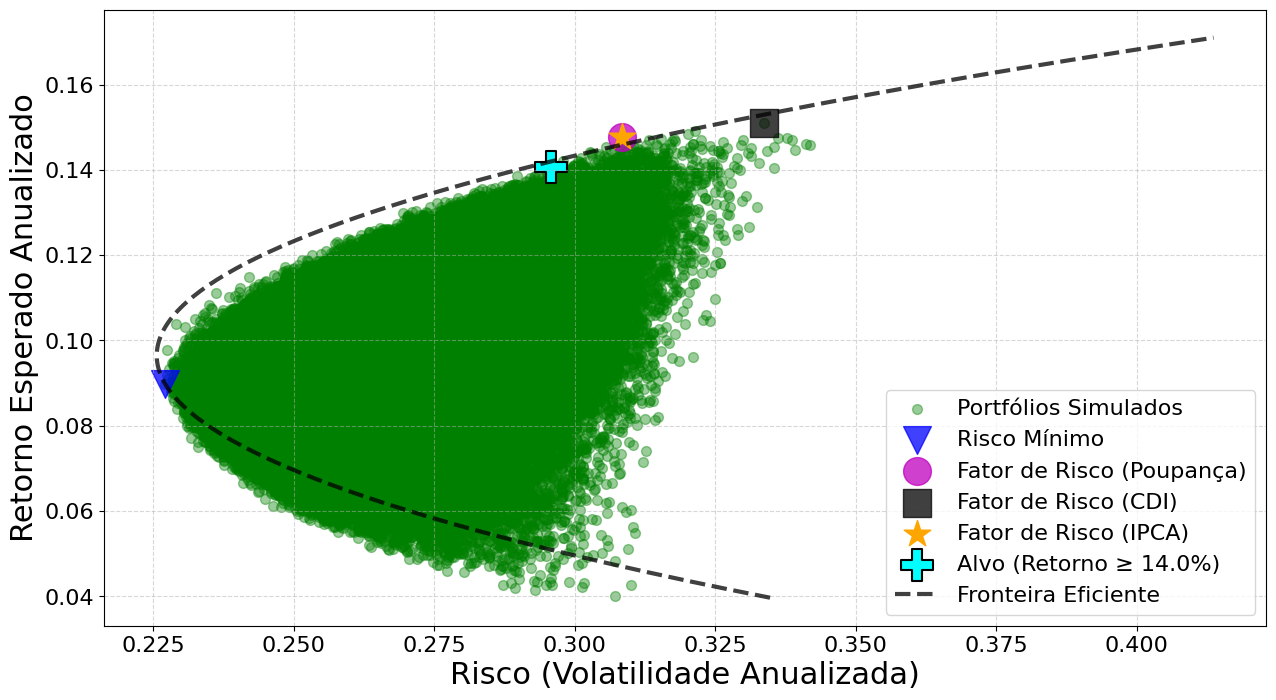

In [8]:
resultados_destaque = plotar_fronteira_eficiente(df)